<div class="langswitch">
  <a href="#lang-en">English</a> · <strong>فارسی</strong>
</div>

# مسائل عملی: مقدارهای آغازین و انتخاب $K$

![](img/banner.png)

گروه علوم کامپیوتر، دانشگاه فردوسی مشهد


## جای این صفحه در درس

بند ۱۴.۳.۱۱ از {cite}`hastie2009esl` (صص ۵۱۸–۵۲۰) دو پرسشی را جمع می‌کند که K-means و K-medoids خودشان نمی‌توانند پاسخ دهند:

1. **از کجا شروع کنیم**، یعنی مجموعهٔ آغازین مرکزها $\{m_1,\dots,m_K\}$ یا اندیس‌های $\{i_1,\dots,i_K\}$؛
2. **چند خوشه**، وقتی مسئله $K$ را نمی‌دهد.

اولی پرسش کمینهٔ محلی است که از [صفحهٔ خانواده‌ها](Three-Families-of-Clustering-Algorithms.ipynb) می‌شناسیم. دومی عمیق‌تر است، چون ابزار بدیهی — اعتبارسنجی متقاطع — اینجا **کار نمی‌کند** و کتاب به‌طور غیرمعمول صریح می‌گوید چرا. جانشینش یک روش ابتکاری است (شکستگی) و خودکارسازی آن (آمارهٔ شکاف).

[صفحهٔ اعتبارسنجی خوشه‌بندی](Clustering-Validation.ipynb) بقیهٔ جعبه‌ابزار را پوشش می‌دهد: خلوص و دیگر سنجه‌های بیرونی، و سیلوئت که همان پرسش را از درون یک خوشه‌بندی پاسخ می‌دهد.

### در پایان باید بتوانید

* مقدارگذاری آغازین گام‌به‌گام رو به جلو را توصیف کنید و بگویید چه چیزی بیش از شروع‌های تصادفی می‌خرد؛
* توضیح دهید چرا اعتبارسنجی متقاطع نمی‌تواند $K$ را برای خوشه‌بندی برگزیند؛
* آمارهٔ شکاف را از ایدهٔ شکستگی به دست آورید و قاعدهٔ (۱۴.۳۹) را بیان کنید؛
* نمودار شکاف را بخوانید، با میله‌های خطا.


## ۱. مقدارهای آغازین

کتاب طیفی از رویه‌ها را می‌آورد، از «انتخاب تصادفی ساده» تا راهبرد عامدانهٔ **گام‌به‌گام رو به جلو**: مرکز اول را برگزین، بعد دومی را چنان که معیار با وجود اولی کمینه شود، بعد سومی را با وجود دو تای اول، و همین‌طور. هر گام جست‌وجویی است روی مشاهده‌ها، پس کل کار $K$ گذر روی داده هزینه دارد، و گرایش دارد مرکزها را پخش کند — مرکز تازه فقط وقتی برگزیده می‌شود که برازش را بهتر کند، و نقطه‌ای درون خوشه‌ای موجود بسیار کم بهبود می‌دهد.

آزمایش زیر دو راهبرد را روی داده‌ای مقایسه می‌کند که تفاوت را نشان می‌دهد: سه گروه که آن‌قدر نزدیک‌اند که برخی شروع‌ها به پیکربندی نادرست همگرا می‌شوند.


In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

rng = np.random.default_rng(1)
# three elongated groups, close enough to be confused
X = np.vstack([
    rng.normal((-1.5, 0.0), (0.9, 2.2), size=(40, 2)),
    rng.normal((1.5, 0.0), (0.9, 2.2), size=(40, 2)),
    rng.normal((0.0, 3.0), (1.6, 0.6), size=(40, 2)),
])


def wcss(X, centres):
    """Sum of squared distances from each point to its nearest centre."""
    d = ((X[:, None, :] - centres[None, :, :]) ** 2).sum(-1)
    return d.min(axis=1).sum()


def forward_stepwise(X, K):
    """Choose centres one at a time, each minimising the criterion so far."""
    first = int(np.argmin(((X - X.mean(axis=0)) ** 2).sum(axis=1)))
    chosen = [first]
    while len(chosen) < K:
        best = None
        for cand in range(len(X)):
            if cand in chosen:
                continue
            trial = X[chosen + [cand]]
            value = wcss(X, trial)
            if best is None or value < best[0]:
                best = (value, cand)
        chosen.append(best[1])
    return X[chosen]


starts = []
for seed in range(50):
    km = KMeans(n_clusters=3, n_init=1, random_state=seed).fit(X)
    starts.append(km.inertia_)
starts = np.array(starts)

centres = forward_stepwise(X, 3)
km_fs = KMeans(n_clusters=3, init=centres, n_init=1, random_state=0).fit(X)

print(f"random starts (50 runs): best {starts.min():8.1f}  "
      f"median {np.median(starts):8.1f}  worst {starts.max():8.1f}")
print(f"runs above the median  : {(starts > np.median(starts)).sum()} of 50")
print(f"forward stepwise       : {km_fs.inertia_:8.1f}")

random starts (50 runs): best    320.8  median    323.7  worst    380.6
runs above the median  : 25 of 50
forward stepwise       :    325.3


شروع گام‌به‌گام رو به جلو در یک کوشش، در چند واحدِ بهترین مقداری که پنجاه شروع تصادفی یافتند می‌افتد و از بدترین مقدار بسیار دور است. روی دادهٔ خوب‌جدا هر راهبردی جواب یکسان می‌دهد و هیچ کدام از این‌ها مهم نیست؛ فاصلهٔ بهترین و بدترینِ بالا بهای انتخاب‌نکردن است.


## ۲. انتخاب $K$: شکستگی، و چرا اعتبارسنجی متقاطع شکست می‌خورد

رویکرد داده‌بنیان این است که نامتشابهی درون‌خوشه‌ای $W_K$ را برای $K = 1, 2, \dots, K_{\max}$ حساب کنیم و منحنی را ببینیم. همیشه کاهش می‌یابد. دلیلش این نیست که خوشه‌های بیشتر از نظر آماری بهتر برازش می‌شوند، و کتاب دقیق است: **حتی روی مجموعهٔ آزمون مستقل** هم معیار کاهش می‌یابد، چون «تعداد زیادی مرکز خوشه گرایش دارند فضای ویژگی را چگال پر کنند و در نتیجه به همهٔ نقطه‌های داده نزدیک باشند». بهایی از بابت مجموعهٔ آزمون پرداخت نمی‌شود، پس درمان معمول یادگیری ماشین — کنار گذاشتن داده — اصلاً $K$ را برنمی‌گزیند. سلول زیر این را نشان می‌دهد.


In [2]:
from sklearn.model_selection import train_test_split

X_tr, X_te = train_test_split(X, test_size=0.4, random_state=0)
print(f"{'K':>2} {'W_K on the held-out data':>28}")
for K in range(1, 9):
    km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X_tr)
    print(f"{K:>2} {wcss(X_te, km.cluster_centers_):26.1f}")

 K     W_K on the held-out data
 1                      321.9
 2                      177.6
 3                      124.8
 4                       85.9
 5                       69.9
 6                       61.3
 7                       57.0
 8                       44.9


از بالا به پایین یکنوا کاهش می‌یابد، پس کمینه همیشه $K = K_{\max}$ است.
خوشه‌بندی پیش‌بینی نیست: چیزی برای پیش‌بینی و خطای کنارگذاشته‌شده‌ای برای پرداخت بهای بیش‌برازش وجود ندارد.

کتاب در عوض از شکل منحنی بهره می‌برد. اگر داده واقعاً $\bar K$ گروه داشته باشد، آن‌گاه برای $K < \bar K$ الگوریتم باید گروه‌های دور از هم را در هم بیامیزد و هر خوشهٔ اضافه $W$ را بسیار کم می‌کند؛ برای $K > \bar K$ خوشهٔ اضافه گروهی را که از قبل جمع‌وجور است می‌شکند و کاهش کوچک است. پس *تفاوت‌های متوالی* $W_K - W_{K+1}$ در $\bar K$ به‌شدت می‌افتند، و همین «شکستگی» است — و روشی ابتکاری. [مثال تومور](Tumor-Microarray-Example.md) ضدِمثال صادقانه است: منحنی آنجا اصلاً شکستگی ندارد و کتاب فقط برای نمایش $K = 3$ را برمی‌گزیند.


## ۳. آمارهٔ شکاف

آمارهٔ شکاف شکستگی چشمی را با یک منحنی مرجع جانشین می‌کند. برای هر $K$ مقدار مشاهده‌شدهٔ $\log W_K$ را با مقدار مورد انتظار در حالتی مقایسه کنید که داده **هیچ خوشه‌ای نداشته باشد**، که از نمونه‌گیری یکنواخت در جعبه‌ای که داده را در بر دارد به دست می‌آید:

$$
G(K) = \frac{1}{B}\sum_{b=1}^{B} \log W_K^{(b)} - \log W_K ,
$$

که در آن $W_K^{(b)}$ روی نمونهٔ یکنواخت $b$ام حساب می‌شود. اگر داده یک تودهٔ واحد باشد، دو منحنی نزدیک‌اند و $G(K)$ نزدیک صفر می‌ماند. اگر $\bar K$ گروه باشد، منحنی مشاهده‌شده تا $\bar K$ سریع‌تر از مرجع می‌افتد و بعد موازی با آن پیش می‌رود، پس شکاف اوج می‌گیرد و سپس صاف می‌شود.

میلهٔ خطا شبیه‌سازی را در نظر می‌گیرد، با $s_K$ انحراف معیار $\log W_K$ روی $B$ نمونه:

$$
s'_K = s_K \sqrt{1 + 1/B},
\qquad
\hat K = \arg\min \left\{ K : G(K) \ge G(K+1) - s'_{K+1} \right\}.
\qquad \text{(14.39)}
$$

قاعده «بیشینه را بگیر» نیست: **کوچک‌ترین** $K$ای را می‌گیرد که شکافش در فاصلهٔ یک میله خطا از شکاف بعدی است، که همان نسخهٔ رسمی «وقتی منحنی صاف شد بایست» است. و وقتی داده یک خوشه داشته باشد هم کار می‌کند — آن‌گاه $\hat K = 1$ — که همان حالتی است که روش شکستگی چیزی برای اشاره ندارد.


In [3]:
def gap_statistic(X, Ks, B=20, seed=0):
    """Observed and uniform-reference log W_K, the gap, and the error bars."""
    rng = np.random.default_rng(seed)
    lo, hi = X.min(axis=0), X.max(axis=0)
    logW_obs, logW_ref, sd_ref = [], [], []
    for K in Ks:
        km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X)
        logW_obs.append(np.log(wcss(X, km.cluster_centers_)))
        ref = []
        for _ in range(B):
            uniform = rng.uniform(lo, hi, size=X.shape)
            kmr = KMeans(n_clusters=K, n_init=3, random_state=0).fit(uniform)
            ref.append(np.log(wcss(uniform, kmr.cluster_centers_)))
        logW_ref.append(np.mean(ref))
        sd_ref.append(np.std(ref))
    logW_obs = np.array(logW_obs)
    logW_ref = np.array(logW_ref)
    gap = logW_ref - logW_obs
    sk = np.array(sd_ref) * np.sqrt(1 + 1 / B)
    return logW_obs, logW_ref, gap, sk


# a data set whose answer is known: three well-separated groups of 30 points
rng_g = np.random.default_rng(7)
Xg = np.vstack([rng_g.normal(c, 0.35, size=(30, 2))
                for c in [(-4.0, 0.0), (4.0, 0.0), (0.0, 6.0)]])

Ks = np.arange(1, 9)
logW_obs, logW_ref, gap, sk = gap_statistic(Xg, Ks, B=20)
logW_obs = logW_obs - logW_obs[0]   # both curves shifted to zero at one cluster
logW_ref = logW_ref - logW_ref[0]

for K, g, s in zip(Ks, gap, sk):
    print(f"K = {K}:  gap = {g:6.3f}   error bar = {s:5.3f}")

K_hat = Ks[-1]                      # smallest K within one error bar of K + 1
for i in range(len(Ks) - 1):
    if gap[i] >= gap[i + 1] - sk[i + 1]:
        K_hat = Ks[i]
        break
print("\nGap estimate of K:", K_hat)

K = 1:  gap = -0.506   error bar = 0.083
K = 2:  gap = -0.385   error bar = 0.083
K = 3:  gap =  3.028   error bar = 0.078
K = 4:  gap =  2.865   error bar = 0.053
K = 5:  gap =  2.795   error bar = 0.069
K = 6:  gap =  2.782   error bar = 0.079
K = 7:  gap =  2.802   error bar = 0.073
K = 8:  gap =  2.833   error bar = 0.058

Gap estimate of K: 3


برآورد چاپ‌شده کوچک‌ترین $K$ای است که شکافش در فاصلهٔ یک میله خطا از شکاف بعدی است، و اینجا همان تعداد گروه‌هایی است که داده از آن‌ها ساخته شده. به شکل آن توجه کنید. برای $K = 1$ و $K = 2$ شکاف *منفی* است: دادهٔ مشاهده‌شده سه گروه جمع‌وجور پخش‌شده در جعبه‌ای بزرگ است، در حالی که مرجع یک تودهٔ پخش است، پس یک یا دو مرکز مرجع را بهتر از دادهٔ اصلی توصیف می‌کنند. در $K = 3$ منحنی مشاهده‌شده فرو می‌ریزد و شکاف بیش از سه واحد می‌جهد — همان شکستگی، ولی سنجیده در برابر یک مرجع نه حدس‌زده با چشم. پس از آن دو منحنی موازی می‌روند و شکاف صاف است.


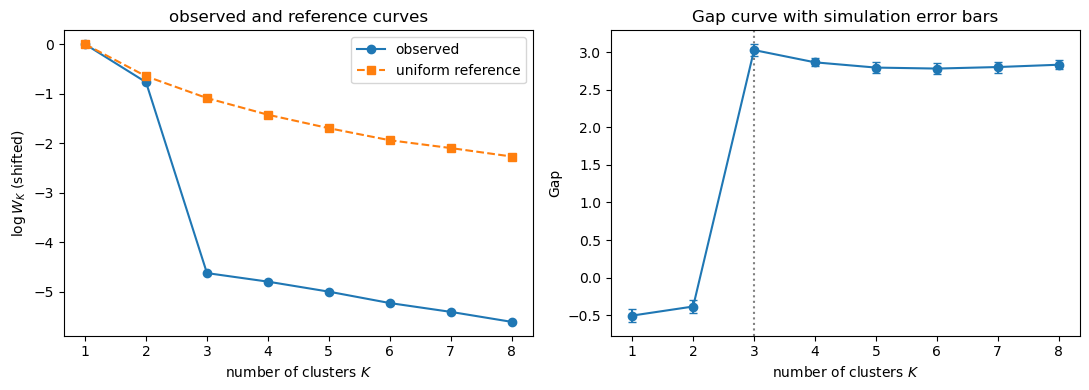

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(Ks, logW_obs, "o-", label="observed")
axes[0].plot(Ks, logW_ref, "s--", label="uniform reference")
axes[0].set_xlabel("number of clusters $K$")
axes[0].set_ylabel(r"$\log W_K$ (shifted)")
axes[0].set_title("observed and reference curves")
axes[0].legend()

axes[1].errorbar(Ks, gap, yerr=sk, fmt="o-", capsize=3)
axes[1].axvline(K_hat, color="grey", linestyle=":")
axes[1].set_xlabel("number of clusters $K$")
axes[1].set_ylabel("Gap")
axes[1].set_title("Gap curve with simulation error bars")
plt.tight_layout()
plt.show()

## ۴. چه چیزی گزارش کنیم

هیچ‌کدام از دو معیار آزمون نیست. هر دو روش‌های ابتکاری‌ای‌اند که به «یک آدم معقول در این تصویر چند گروه می‌بیند» پاسخ می‌دهند، و راه صادقانهٔ به‌کارگیری‌شان چنین است:

* تمام منحنی $W_K$ را گزارش کنید، نه فقط $K$ برگزیده را؛
* بگویید کدام قاعده $K$ را برگزید — خود مسئله (شرکتی با $K$ فروشنده)، شکستگی، آمارهٔ شکاف، یا یک سنجهٔ اعتبارسنجی؛
* پایداری را بسنجید: روی نمونه‌های بوت‌استرپ دوباره خوشه‌بندی کنید و ببینید همان گروه‌ها بازمی‌گردند؛
* یادتان باشد تعداد شروع‌ها و تعداد خوشه‌ها هر دو بخشی از جواب‌اند، همان‌گونه که بخش اول نشان داد.


## خلاصه

* مقدارگذاری آغازین یک انتخاب است: شروع‌های تصادفی تکرار می‌خواهند، گام‌به‌گام رو به جلو مرکزها را یکی‌یکی و چنان برمی‌گزیند که معیار کمینه شود و معمولاً نزدیک بهترین جوابی می‌افتد که شروع‌های تصادفی متعدد می‌یابند.
* $W_K$ **حتی روی دادهٔ کنارگذاشته‌شده** یکنوا کاهش می‌یابد، چون مرکزها فضای ویژگی را پر می‌کنند؛ پس اعتبارسنجی متقاطع نمی‌تواند $K$ را برگزیند.
* شکستگی در $W_K$ یا در $\log W_K$ پاسخ ابتکاری است، و می‌تواند غایب باشد — مانند مثال تومور.
* آمارهٔ شکاف $\log W_K$ را با یک مرجع یکنواخت مقایسه می‌کند و (۱۴.۳۹) کوچک‌ترین $K$ را در فاصلهٔ یک میله خطا از بعدی برمی‌گزیند؛ وقتی جواب درست یک خوشه باشد هم یک خوشه برمی‌گرداند.
* هر قاعده‌ای به کار می‌برید، منحنی و قاعده را گزارش کنید.


## تمرین‌ها

1. دویست شروع تصادفی روی دادهٔ بخش ۱ اجرا کنید و هیستوگرام مقدارهای نهایی را رسم کنید. چند کمینهٔ محلی متمایز هست؟
2. قاعدهٔ شکستگی را کد کنید: نخستین $K$ای که $W_K - W_{K+1}$ زیر کسری از تفاوت قبلی بیفتد. پاسخ چقدر به آن کسر حساس است؟
3. آمارهٔ شکاف را روی دادهٔ [مثال تومور](Tumor-Microarray-Example.md) (یا ۶۴ نقطه از سه گاوسی هم‌پوشان) به کار ببرید و ببینید شکستگی‌ای می‌یابد که منحنی نشان نمی‌دهد.
4. محاسبهٔ شکاف را با $B = 5$ و $B = 100$ تکرار کنید. بر میله‌های خطا و بر $\hat K$ چه می‌آید؟
5. با شبیه‌سازی نشان دهید آمارهٔ شکاف برای دادهٔ یک گاوسی $\hat K = 1$ برمی‌گرداند و قاعدهٔ شکستگی نه.
6. گام‌به‌گام رو به جلو مرکزها را برای کمینه‌کردن $W$ برمی‌گزیند؛ K-means++ آن‌ها را با احتمالی متناسب با مجذور فاصله تا نزدیک‌ترین مرکز برگزیده نمونه‌گیری می‌کند. این دو را با ۱۰۰ شروع مقایسه کنید.


## منابع

* مقدارگذاری آغازین گام‌به‌گام رو به جلو، استدلال علیه اعتبارسنجی متقاطع، شکستگی، آمارهٔ شکاف، (۱۴.۳۹) و شکل ۱۴.۱۱: بند ۱۴.۳.۱۱ از {cite}`hastie2009esl`، صص ۵۱۸–۵۲۰؛ آمارهٔ شکاف از Tibshirani, Walther and Hastie (2001) است که همان‌جا ارجاع داده شده.
* غیبت شکستگی روی دادهٔ واقعی: [مثال تومور](Tumor-Microarray-Example.md) و شکل ۱۴.۸ کتاب.
* راه‌های دیگر داوری یک خوشه‌بندی — خلوص، رند، جاکارد، سیلوئت: [اعتبارسنجی خوشه‌بندی](Clustering-Validation.ipynb).
